--- RESUMEN TRANSACCIONES POR CATEGORÍA ---
+-----------+------------+-----------+--------------+
|  Categoria|Total_Ventas|Monto_Total|Promedio_Monto|
+-----------+------------+-----------+--------------+
|       Ropa|           2|      165.0|          82.5|
|Electronica|           2|     3500.5|       1750.25|
|      Hogar|           2|      376.0|         188.0|
+-----------+------------+-----------+--------------+



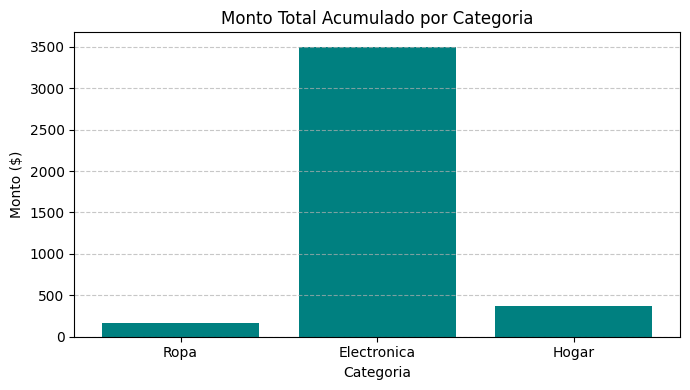

In [1]:
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, sum, avg, round, when

# 1. Crear la sesión de Spark
spark = SparkSession.builder \
    .appName("AnalisisBatchUNAD") \
    .getOrCreate()

# 2. Cargar/Simular el conjunto de datos
datos = [
    ("TX101", "Electronica", 1200.50, "Aprobada"),
    ("TX102", "Ropa", 45.00, "Aprobada"),
    ("TX103", "Electronica", 850.00, "Rechazada"),
    ("TX104", "Hogar", 300.20, "Aprobada"),
    ("TX105", "Ropa", 120.00, "Aprobada"),
    ("TX106", "Electronica", 2300.00, "Aprobada"),
    ("TX107", "Hogar", 75.80, "Aprobada")
]
columnas = ["ID_Transaccion", "Categoria", "Monto", "Estado"]

df = spark.createDataFrame(datos, columnas)

# 3. Limpieza y Transformación (Filtrado de aprobadas y clasificación)
df_limpio = df.filter(col("Estado") == "Aprobada")
df_transformado = df_limpio.withColumn(
    "Tipo_Monto",
    when(col("Monto") >= 500, "Alto Valor").otherwise("Estandar")
)

# 4. Análisis Exploratorio de Datos (EDA)
print("--- RESUMEN TRANSACCIONES POR CATEGORÍA ---")
df_resumen = df_transformado.groupBy("Categoria").agg(
    count("ID_Transaccion").alias("Total_Ventas"),
    round(sum("Monto"), 2).alias("Monto_Total"),
    round(avg("Monto"), 2).alias("Promedio_Monto")
)
df_resumen.show()

# 5. Visualización de los resultados
pdf_resumen = df_resumen.toPandas()
plt.figure(figsize=(7, 4))
plt.bar(pdf_resumen["Categoria"], pdf_resumen["Monto_Total"], color='teal')
plt.title("Monto Total Acumulado por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Monto ($)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("grafico_batch.png")
plt.show()